[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_blocktime/BA_L1_blocktime.ipynb)

# BA_L1_blocktime: Blocks Arrive Faster Than Every 10 Minutes

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Daily mean time between Bitcoin blocks (30-day mean) against the 10-minute target, and the histogram of the difficulty adjustments found in the daily difficulty series, November 2014 to 8 October 2025; with the last adjustment worked out step by step.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

The on-chain files give, for each day, the mean time between Bitcoin blocks (minutes) and the mining difficulty $D$.
The difficulty is constant within an **epoch** of 2 016 blocks; at the next epoch it becomes
$D_{\text{new}} = D_{\text{old}} \times 20\,160/m$, with $m$ the minutes the last 2 016 blocks took. Because the daily
file averages the difficulty over the blocks of a day, an epoch is a run of at least two equal days; the percentage
change between consecutive epochs is one adjustment.

**How to read the chart.** Left: block time, 30-day mean, against the 10-minute target (dashed red). Below the line,
blocks came faster than planned, and the next adjustment raises the difficulty. Right: the adjustments; most are
positive because the hash rate grew over the sample.

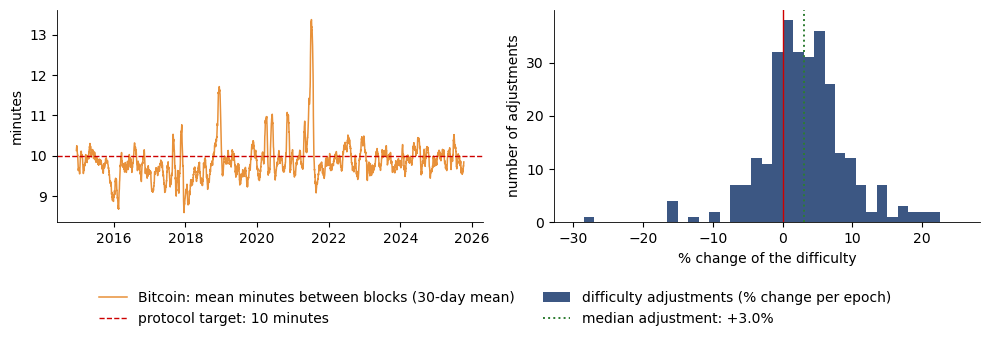

Mean time between blocks, 28 Nov 2014 - 08 Oct 2025: 9.86 minutes, i.e. 146.1 blocks a day on average (target 144)
Share of days with a mean block time below 10 minutes: 59%
Difficulty adjustments found: 291; median +2.99%; upward 74% of the time
30-day mean block time: from 8.59 (Dec 2017) to 13.37 minutes (Jul 2021)
Largest fall -27.9% (epoch starting 04 July 2021); largest rise +21.5% (14 May 2021)


In [5]:
# Bitcoin: mean time between blocks (minutes, daily) and the difficulty adjustments
block_min = load_onchain('blocktime')['BTC'].dropna()
diff_btc = load_onchain('miningdifi')['BTC'].dropna()

# the daily difficulty is constant within an epoch of 2 016 blocks; an epoch is a run of at least two equal days
run_id = (diff_btc != diff_btc.shift()).cumsum()
runs = diff_btc.groupby(run_id).agg(['first', 'size'])
runs.index = diff_btc.groupby(run_id).apply(lambda s: s.index[0])
epochs = runs.loc[runs['size'] >= 2, 'first']
adj_pct = (100 * (epochs / epochs.shift() - 1)).dropna()
adj_pct = adj_pct[adj_pct.abs() > 1e-3]                 # a level that repeats after a one-day glitch is not an adjustment

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
block_30 = block_min.rolling(30, min_periods=20).mean()
ax[0].plot(block_30, color=BTC, lw=1.1, label='Bitcoin: mean minutes between blocks (30-day mean)')
ax[0].axhline(10, color=RED, ls='--', lw=1, label='protocol target: 10 minutes')
ax[0].set_ylabel('minutes')
ax[1].hist(adj_pct.clip(-30, 25), bins=np.arange(-30, 26, 1.5), color=BLUE, alpha=0.85, label='difficulty adjustments (% change per epoch)')
ax[1].axvline(0, color=RED, lw=1)
ax[1].axvline(adj_pct.median(), color=GREEN, ls=':', lw=1.4, label=f'median adjustment: {adj_pct.median():+.1f}%')
ax[1].set_xlabel('% change of the difficulty'); ax[1].set_ylabel('number of adjustments')
legend_below(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l1_blocktime')

print(f'Mean time between blocks, {block_min.index[0]:%d %b %Y} - {block_min.index[-1]:%d %b %Y}: {block_min.mean():.2f} minutes, '
      f'i.e. {1440 / block_min.mean():.1f} blocks a day on average (target 144)')
print(f'Share of days with a mean block time below 10 minutes: {100 * (block_min < 10).mean():.0f}%')
print(f'Difficulty adjustments found: {len(adj_pct)}; median {adj_pct.median():+.2f}%; '
      f'upward {100 * (adj_pct > 0).mean():.0f}% of the time')
print(f'30-day mean block time: from {block_30.min():.2f} ({block_30.idxmin():%b %Y}) to {block_30.max():.2f} minutes ({block_30.idxmax():%b %Y})')
print(f'Largest fall {adj_pct.min():.1f}% (epoch starting {adj_pct.idxmin():%d %B %Y}); '
      f'largest rise {adj_pct.max():+.1f}% ({adj_pct.idxmax():%d %B %Y})')

The last adjustment in the data, read backwards: $m = 20\,160 \times D_{\text{old}}/D_{\text{new}}$.

In [6]:
# worked example: the last adjustment in the data, D_new = D_old x 20 160 / actual minutes
d_old, d_new = epochs.iloc[-2], epochs.iloc[-1]
factor = d_new / d_old
actual_min = 20160 / factor
print(f'Epoch starting {epochs.index[-2]:%d %B %Y}: D_old = {d_old:.4e}')
print(f'Epoch starting {epochs.index[-1]:%d %B %Y}: D_new = {d_new:.4e}')
print(f'Factor D_new / D_old = {factor:.4f}  (difficulty {100 * (factor - 1):+.2f}%)')
print(f'Implied duration of the previous 2 016 blocks: 20 160 / {factor:.4f} = {actual_min:,.0f} minutes = {actual_min / 1440:.2f} days')
print(f'Implied mean time between blocks: {actual_min:,.0f} / 2 016 = {actual_min / 2016:.2f} minutes')
in_epoch = block_min.loc[epochs.index[-2]:epochs.index[-1] - pd.Timedelta(days=1)]
print(f'Check with the block-time file, {in_epoch.index[0]:%d %b} - {in_epoch.index[-1]:%d %b %Y}: mean {in_epoch.mean():.2f} minutes')

Epoch starting 19 September 2025: D_old = 1.4234e+14
Epoch starting 02 October 2025: D_new = 1.5084e+14
Factor D_new / D_old = 1.0597  (difficulty +5.97%)
Implied duration of the previous 2 016 blocks: 20 160 / 1.0597 = 19,024 minutes = 13.21 days
Implied mean time between blocks: 19,024 / 2 016 = 9.44 minutes
Check with the block-time file, 19 Sep - 01 Oct 2025: mean 9.52 minutes
